[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/04-machine-learning/14_applied-ml.ipynb)

*Machine Learning from Scratch · Notebook 14 of 14*

# Applied ML: Features, Anomalies, Text & Vision

The practical skills between textbook ML and real projects: one-hot and target encoding, date features, filtering redundant features, spotting leakage, four ways to find anomalies and how to score them, judging a t-SNE/UMAP picture, bag-of-words, Naive Bayes text classification, n-grams, entity tagging and scoring, and the core of object detection — IoU, non-max suppression, matching detections — plus what transfer learning actually trains.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** Textbook ML hands you clean numbers; real projects hand you messy columns, rare anomalies, raw text and images — this is the toolkit for turning them into something a model can use.

**What interviewers really test here:** Encoding and leakage, choosing an anomaly method and scoring it, reading t-SNE plots safely, text baselines vs transformers, NER scoring, IoU, NMS, mAP and transfer learning.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. Feature engineering *(Basics)*
- [ ] 2. Finding anomalies *(Core)*
- [ ] 3. Pictures of high-dimensional data *(Core)*
- [ ] 4. Classic NLP *(Core)*
- [ ] 5. Computer vision: detection and transfer learning *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Which encoder for which column?

| Column | Encoding |
| --- | --- |
| few categories, no order | one-hot |
| many categories (ids, cities) | target encoding (cross-fitted), hashing, or embeddings |
| ordered categories (S/M/L) | ordinal integers |
| dates and times | parts (weekday, month, hour) + recency |
| text | counts/TF-IDF, or embeddings from a language model |



Tree models (gradient boosting) need less scaling and handle interactions themselves; linear models and k-NN need scaled, well-encoded inputs.

### Detection metrics

- **IoU ≥ 0.5** is the classic match threshold (PASCAL VOC); COCO averages mAP over IoU 0.5–0.95.
- **Precision**: how many predicted boxes were right. **Recall**: how many objects were found.
- **mAP**: area under the precision–recall curve, averaged over classes.

---
# Part 2: Lessons, step by step

## Lesson 1: Feature engineering

*Level: Basics*

Models only see numbers, and how you build them often matters more than which model you pick.




- **Categories**: one-hot for a few values; **target encoding** (mean target per category, smoothed and computed out-of-fold) for many values like city or product id; never plain integer codes for unordered categories in linear models.
- **Dates**: weekday, month, holiday flags, and *recency* (days since the last event) usually beat the raw date.
- **Ratios and interactions**: spend per visit, price × quantity — domain knowledge turned into columns.
- **Selection**: drop constant and near-duplicate columns; check importance on held-out data.
- **Leakage**: any column recorded after the outcome (a refund flag when predicting churn) makes offline scores great and production useless. A near-perfect single feature is a red flag.



```python
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, TargetEncoder, StandardScaler
prep = ColumnTransformer([
    ("few", OneHotEncoder(handle_unknown="ignore"), ["plan", "region"]),
    ("many", TargetEncoder(), ["city"]),            # cross-fitted internally to avoid leakage
    ("num", StandardScaler(), ["tenure", "spend"]),
])
```

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q10](#q10), [Q2](#q2), [Q11](#q11), [Q12](#q12). Try one now, or carry on and do them in Part 3.

## Lesson 2: Finding anomalies

*Level: Core*

Fraud, faulty sensors and data bugs are rare and usually unlabelled. Start simple, then add context:



| Method | Good for | Watch out |
| --- | --- | --- |
| z-score | roughly normal data | a huge outlier inflates the std and hides others |
| IQR fences / MAD | skewed data, robust | one feature at a time |
| k-NN distance | several clusters, many features | needs scaling; slow on big data without an index |
| Isolation Forest | many features, big data | random; set `random_state` |
| Seasonal baselines | time series | see the time-series topic |



Evaluate with labelled examples when you have some: precision@k (how many of the top alerts are real) and average precision — never accuracy.



```python
from sklearn.ensemble import IsolationForest
iso = IsolationForest(contamination=0.01, random_state=0).fit(X)
scores = -iso.score_samples(X)          # higher = more anomalous
```

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

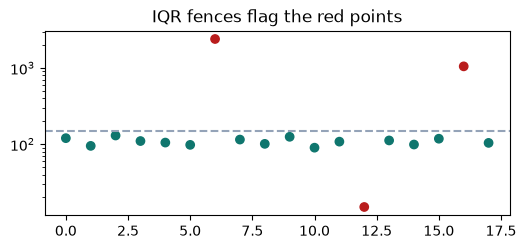

In [2]:
def outlier_picture():
    amounts = np.array([120, 95, 130, 110, 105, 98, 2400, 115, 101, 125, 90, 108, 15, 112, 99, 118, 1050, 104])
    q1, q3 = np.percentile(amounts, [25, 75])
    hi = q3 + 1.5 * (q3 - q1)
    fig, ax = plt.subplots(figsize=(6, 2.4))
    ax.scatter(range(len(amounts)), amounts, c=["#b91c1c" if a > hi or a < q1 - 1.5 * (q3 - q1) else "#0f766e" for a in amounts])
    ax.axhline(hi, ls="--", color="#94a3b8")
    ax.set_yscale("log"); ax.set_title("IQR fences flag the red points")


outlier_picture()

**✏️ Your turn:** you now have what you need for [Q3](#q3), [Q4](#q4), [Q13](#q13), [Q14](#q14), [Q15](#q15). Try one now, or carry on and do them in Part 3.

## Lesson 3: Pictures of high-dimensional data

*Level: Core*

**PCA** is linear and keeps global structure. **t-SNE** and **UMAP** are non-linear and great at showing clusters — but they can stretch distances and invent closeness. Cluster sizes and gaps between clusters in a t-SNE plot mean little. Check a picture with **trustworthiness** (are 2-D neighbours real neighbours?) before drawing conclusions.



```python
from sklearn.manifold import TSNE, trustworthiness
emb = TSNE(n_components=2, perplexity=30, random_state=0).fit_transform(X)
trustworthiness(X, emb, n_neighbors=10)      # close to 1 = faithful
import umap; emb = umap.UMAP(n_neighbors=15, min_dist=0.1).fit_transform(X)
```

**✏️ Your turn:** you now have what you need for [Q20](#q20). Try one now, or carry on and do them in Part 3.

## Lesson 4: Classic NLP

*Level: Core*

Before reaching for an LLM, try the fast baselines: they're cheap, explainable and often good enough.




- **Bag of words / n-grams** → counts or TF-IDF → **Naive Bayes** or logistic regression. Bigrams capture "not good" and "fast delivery".
- **Named-entity recognition** labels tokens with BIO tags and is scored on whole entities.
- **Transformers** (BERT-style) fine-tuned on your labels beat both when data and budget allow; LLMs with a prompt work with no training data.



```python
from sklearn.pipeline import make_pipeline
clf = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2), LogisticRegression(max_iter=1000)).fit(texts, y)

import spacy; [(e.text, e.label_) for e in spacy.load("en_core_web_sm")("Asha flew to Pune").ents]
from transformers import pipeline; pipeline("sentiment-analysis")("Great battery!")
```

**✏️ Your turn:** you now have what you need for [Q5](#q5), [Q16](#q16), [Q6](#q6), [Q7](#q7), [Q17](#q17). Try one now, or carry on and do them in Part 3.

## Lesson 5: Computer vision: detection and transfer learning

*Level: Advanced*

**Object detection** predicts boxes with classes and scores. Three ideas run through every detector (YOLO, Faster R-CNN, DETR):




- **IoU** measures box overlap.
- **Non-maximum suppression** removes duplicate boxes for one object.
- Predictions are **matched** to ground truth at an IoU threshold to count TP/FP/FN; averaging precision over recall levels and classes gives **mAP**.



**Transfer learning** starts from a model pretrained on millions of images, freezes most of it, and trains a small head on your few hundred labelled images — far less data and compute.



```python
import torchvision
model = torchvision.models.resnet50(weights="IMAGENET1K_V2")
for p in model.parameters():
    p.requires_grad = False                          # freeze the backbone
model.fc = torch.nn.Linear(model.fc.in_features, 5)  # new head for 5 classes

from torchvision.ops import box_iou, nms
keep = nms(boxes, scores, iou_threshold=0.5)
from ultralytics import YOLO; YOLO("yolo11n.pt")("street.jpg")
```

**✏️ Your turn:** you now have what you need for [Q8](#q8), [Q18](#q18), [Q19](#q19), [Q9](#q9). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

**▶ Run this cell before the questions.** It sets up the data and tools they share.

In [3]:
from scipy import stats

import math

from sklearn.feature_extraction.text import CountVectorizer

import re

from collections import Counter


<a id="q1"></a>
### Q1. One-Hot Encode Categories

🟢 Warm-up · *Including unseen values*

Learn the categories from `train` (sorted), then one-hot encode both lists. A category never seen in training becomes a row of zeros instead of crashing — that's `handle_unknown='ignore'`. Return `(categories, train rows, test rows)`.

**Examples**

- `train = ['red', 'green', 'blue', 'green'], test = ['green', 'purple', 'red']` → `(['blue', 'green', 'red'], [[0, 0, 1], [0, 1, 0], [1, 0, 0], [0, 1, 0]], [[0, 1, 0], [0, 0, 0], [0, 0, 1]])`

In [ ]:
from sklearn.preprocessing import OneHotEncoder

def one_hot(train, test):
    """
    Learn the categories from train (sorted), then one-hot encode both lists. A
    category never seen in training becomes a row of zeros instead of crashing —
    that's handle_unknown='ignore'. Return (categories, train rows, test rows).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(one_hot, [
    ((['red', 'green', 'blue', 'green'], ['green', 'purple', 'red']), (['blue', 'green', 'red'], [[0, 0, 1], [0, 1, 0], [1, 0, 0], [0, 1, 0]], [[0, 1, 0], [0, 0, 0], [0, 0, 1]])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Build a column index and fill lists.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`OneHotEncoder(handle_unknown='ignore', sparse_output=False)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Build a column index and fill lists.

```python
def one_hot(train, test):
    cats = sorted(set(train))
    def enc(values):
        return [[1 if v == c else 0 for c in cats] for v in values]
    return (cats, enc(train), enc(test))
```

**Cost:** O(n · c) time, O(n · c) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `OneHotEncoder(handle_unknown='ignore', sparse_output=False)`.

```python
def one_hot(train, test):
    oh = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(np.array(train).reshape(-1, 1))
    return (list(oh.categories_[0]), oh.transform(np.array(train).reshape(-1, 1)).astype(int).tolist(),
            oh.transform(np.array(test).reshape(-1, 1)).astype(int).tolist())
```

**Cost:** O(n · c) time, O(n · c) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Build a column index and fill lists. That costs O(n · c) time and O(n · c) space."

"I can do better: `OneHotEncoder(handle_unknown='ignore', sparse_output=False)`. That's O(n · c) time and O(n · c) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/applied-ml/one-hot-encode-categories)

<a id="q2"></a>
### Q2. Features From Dates

🟢 Warm-up · *Day of week, month, weekend, recency*

For each date string, return `(weekday 0=Monday, month, is_weekend, days before ref)`. Raw dates are useless to most models; these derived features carry the signal (weekly patterns, seasonality, recency).

**Examples**

- `days = ['2026-11-27', '2026-11-29', '2026-01-01', '2025-12-25'], ref = '2026-11-30'` → `[(4, 11, False, 3), (6, 11, True, 1), (3, 1, False, 333), (3, 12, False, 340)]`

In [ ]:
from datetime import date

def date_features(days, ref):
    """
    For each date string, return (weekday 0=Monday, month, is_weekend, days
    before ref). Raw dates are useless to most models; these derived features
    carry the signal (weekly patterns, seasonality, recency).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(date_features, [
    ((['2026-11-27', '2026-11-29', '2026-01-01', '2025-12-25'], '2026-11-30'), [(4, 11, False, 3), (6, 11, True, 1), (3, 1, False, 333), (3, 12, False, 340)]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

`date.fromisoformat` in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

pandas `.dt` accessors on a whole column.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** `date.fromisoformat` in a loop.

```python
def date_features(days, ref):
    r = date.fromisoformat(ref)
    out = []
    for d in days:
        x = date.fromisoformat(d)
        out.append((x.weekday(), x.month, x.weekday() >= 5, (r - x).days))
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** pandas `.dt` accessors on a whole column.

```python
def date_features(days, ref):
    s = pd.to_datetime(pd.Series(days))
    df = pd.DataFrame({"wd": s.dt.dayofweek, "m": s.dt.month, "we": s.dt.dayofweek >= 5, "age": (pd.Timestamp(ref) - s).dt.days})
    return [(int(a), int(b), bool(c), int(d)) for a, b, c, d in df.itertuples(index=False)]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: `date.fromisoformat` in a loop. That costs O(n) time and O(n) space."

"I can do better: pandas `.dt` accessors on a whole column. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/applied-ml/features-from-dates)

<a id="q3"></a>
### Q3. Z-Score Outliers

🟢 Warm-up · *Distance from the mean in standard deviations*

Return the indexes of values whose z-score (population standard deviation) has absolute value above `limit`. Notice how one huge value inflates the standard deviation and hides others: the second test removes the 2,400 and the 1,050 suddenly appears. That's the reason for the robust methods next.

**Examples**

- `values = [120, 95, 130, 110, 105, 98, 2400, 115, 101, 125, 90, 108, 15, 112, 99, 118, 1050, 104], limit = 2.0` → `[6]`
- `values = [120, 95, 130, 110, 105, 98, 100, 115, 101, 125, 90, 108, 15, 112, 99, 118, 1050, 104], limit = 2.0` → `[16]`

In [ ]:
def zscore_outliers(values, limit):
    """
    Return the indexes of values whose z-score (population standard deviation)
    has absolute value above limit. Notice how one huge value inflates the
    standard deviation and hides others: the second test removes the 2,400 and
    the 1,050 suddenly appears. That's the reason for the robust methods next.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(zscore_outliers, [
    (([120, 95, 130, 110, 105, 98, 2400, 115, 101, 125, 90, 108, 15, 112, 99, 118, 1050, 104], 2.0), [6]),
    (([120, 95, 130, 110, 105, 98, 100, 115, 101, 125, 90, 108, 15, 112, 99, 118, 1050, 104], 2.0), [16]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Mean and standard deviation by hand.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`scipy.stats.zscore`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Mean and standard deviation by hand.

```python
def zscore_outliers(values, limit):
    m = sum(values) / len(values)
    sd = math.sqrt(sum((v - m) ** 2 for v in values) / len(values))
    return [i for i, v in enumerate(values) if abs((v - m) / sd) > limit]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `scipy.stats.zscore`.

```python
def zscore_outliers(values, limit):
    return np.flatnonzero(np.abs(stats.zscore(values)) > limit).tolist()
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Mean and standard deviation by hand. That costs O(n) time and O(n) space."

"I can do better: `scipy.stats.zscore`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/applied-ml/z-score-outliers)

<a id="q4"></a>
### Q4. Tukey's IQR Fences

🟢 Warm-up · *The box-plot rule*

Compute Q1 and Q3 (linear interpolation, like NumPy's default), the fences `Q1 − 1.5·IQR` and `Q3 + 1.5·IQR`, and return `(q1, q3, low fence, high fence, outlier indexes)`, rounded to 2.

**Examples**

- `values = [120, 95, 130, 110, 105, 98, 2400, 115, 101, 125, 90, 108, 15, 112, 99, 118, 1050, 104]` → `(99.5, 119.5, 69.5, 149.5, [6, 12, 16])`

In [ ]:
def iqr_outliers(values):
    """
    Compute Q1 and Q3 (linear interpolation, like NumPy's default), the fences
    Q1 − 1.5·IQR and Q3 + 1.5·IQR, and return (q1, q3, low fence, high fence,
    outlier indexes), rounded to 2.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(iqr_outliers, [
    (([120, 95, 130, 110, 105, 98, 2400, 115, 101, 125, 90, 108, 15, 112, 99, 118, 1050, 104],), (99.5, 119.5, 69.5, 149.5, [6, 12, 16])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Sort and interpolate percentiles by hand.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.percentile`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Sort and interpolate percentiles by hand.

```python
def iqr_outliers(values):
    s = sorted(values)
    def pct(p):
        pos = (len(s) - 1) * p
        lo = int(pos)
        frac = pos - lo
        return s[lo] + (s[min(lo + 1, len(s) - 1)] - s[lo]) * frac
    q1, q3 = pct(0.25), pct(0.75)
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    return (round(q1, 2), round(q3, 2), round(lo, 2), round(hi, 2), [i for i, v in enumerate(values) if v < lo or v > hi])
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `np.percentile`.

```python
def iqr_outliers(values):
    q1, q3 = np.percentile(values, [25, 75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    v = np.array(values)
    return (round(float(q1), 2), round(float(q3), 2), round(float(lo), 2), round(float(hi), 2), np.flatnonzero((v < lo) | (v > hi)).tolist())
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Sort and interpolate percentiles by hand. That costs O(n log n) time and O(n) space."

"I can do better: `np.percentile`. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/applied-ml/tukeys-iqr-fences)

<a id="q5"></a>
### Q5. Bag of Words

🟢 Warm-up · *Text → a count matrix*

Lower-case each text, keep tokens of 2+ word characters (`\b\w\w+\b`), build a sorted vocabulary and count each word per text. Return `(vocabulary, count rows)` for the first three reviews — exactly what `CountVectorizer` does.

**Examples**

- `texts = ['Great battery and great camera', 'Battery died fast, terrible phone', 'Love the camera, love the screen']` → `(['and', 'battery', 'camera', 'died', 'fast', 'great', 'love', 'phone', 'screen', 'terrible', 'the'], [[1, 1, 1, 0, 0, 2, 0, 0, 0, 0, 0], [0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0], [0, 0, 1, 0, 0, 0, 2, 0, 1, 0, 2]])`

In [ ]:
def bag_of_words(texts):
    """
    Lower-case each text, keep tokens of 2+ word characters (\b\w\w+\b), build a
    sorted vocabulary and count each word per text. Return (vocabulary, count
    rows) for the first three reviews — exactly what CountVectorizer does.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(bag_of_words, [
    ((['Great battery and great camera', 'Battery died fast, terrible phone', 'Love the camera, love the screen'],), (['and', 'battery', 'camera', 'died', 'fast', 'great', 'love', 'phone', 'screen', 'terrible', 'the'], [[1, 1, 1, 0, 0, 2, 0, 0, 0, 0, 0], [0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0], [0, 0, 1, 0, 0, 0, 2, 0, 1, 0, 2]])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Regex tokens, a vocabulary list and Counters.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`CountVectorizer().fit_transform`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Regex tokens, a vocabulary list and Counters.

```python
def bag_of_words(texts):
    toks = [re.findall(r"\b\w\w+\b", t.lower()) for t in texts]
    vocab = sorted({w for ts in toks for w in ts})
    rows = []
    for ts in toks:
        c = Counter(ts)
        rows.append([c[w] for w in vocab])
    return (vocab, rows)
```

**Cost:** O(total tokens + n · v) time, O(n · v) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `CountVectorizer().fit_transform`.

```python
def bag_of_words(texts):
    cv = CountVectorizer()
    X = cv.fit_transform(texts)
    return (cv.get_feature_names_out().tolist(), X.toarray().tolist())
```

**Cost:** O(total tokens + n · v) time, O(n · v) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Regex tokens, a vocabulary list and Counters. That costs O(total tokens + n · v) time and O(n · v) space."

"I can do better: `CountVectorizer().fit_transform`. That's O(total tokens + n · v) time and O(n · v) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/applied-ml/bag-of-words)

<a id="q6"></a>
### Q6. Most Common Bigrams

🟢 Warm-up · *Two-word phrases*

Single words lose phrases like 'not good' or 'fast delivery'. Count two-word sequences (same tokenising as before) across all texts and return the `k` most frequent with counts, ties alphabetical.

**Examples**

- `texts = ['fast delivery and great price', 'great price, fast delivery', 'slow delivery and bad price', 'great price again'], k = 3` → `[('great price', 3), ('delivery and', 2), ('fast delivery', 2)]`

In [ ]:
def top_bigrams(texts, k):
    """
    Single words lose phrases like 'not good' or 'fast delivery'. Count two-word
    sequences (same tokenising as before) across all texts and return the k most
    frequent with counts, ties alphabetical.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(top_bigrams, [
    ((['fast delivery and great price', 'great price, fast delivery', 'slow delivery and bad price', 'great price again'], 3), [('great price', 3), ('delivery and', 2), ('fast delivery', 2)]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

zip neighbouring tokens into a Counter.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`CountVectorizer(ngram_range=(2, 2))` summed over rows.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** zip neighbouring tokens into a Counter.

```python
def top_bigrams(texts, k):
    c = Counter()
    for t in texts:
        toks = re.findall(r"\b\w\w+\b", t.lower())
        c.update(" ".join(p) for p in zip(toks, toks[1:]))
    return sorted(c.items(), key=lambda x: (-x[1], x[0]))[:k]
```

**Cost:** O(tokens) time, O(b) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `CountVectorizer(ngram_range=(2, 2))` summed over rows.

```python
def top_bigrams(texts, k):
    cv = CountVectorizer(ngram_range=(2, 2))
    totals = np.asarray(cv.fit_transform(texts).sum(axis=0)).ravel()
    pairs = zip(cv.get_feature_names_out(), totals)
    return sorted(((w, int(n)) for w, n in pairs), key=lambda x: (-x[1], x[0]))[:k]
```

**Cost:** O(tokens) time, O(b) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: zip neighbouring tokens into a Counter. That costs O(tokens) time and O(b) space."

"I can do better: `CountVectorizer(ngram_range=(2, 2))` summed over rows. That's O(tokens) time and O(b) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/applied-ml/most-common-bigrams)

<a id="q7"></a>
### Q7. Tag Entities With BIO Labels

🟢 Warm-up · *How NER data is labelled*

Named-entity recognition labels every token: `B-TYPE` at the start of an entity, `I-TYPE` inside it, `O` outside. Given tokens and entity spans `(start, end exclusive, type)`, return the tags.

**Examples**

- `tokens = ['Asha', 'Kulkarni', 'flew', 'from', 'New', 'Delhi', 'to', 'Pune', 'on', 'Air', 'India', '.'], spans = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 8, 'LOC'), (9, 11, 'ORG')]` → `['B-PER', 'I-PER', 'O', 'O', 'B-LOC', 'I-LOC', 'O', 'B-LOC', 'O', 'B-ORG', 'I-ORG', 'O']`

In [ ]:
def bio_tags(tokens, spans):
    """
    Named-entity recognition labels every token: B-TYPE at the start of an
    entity, I-TYPE inside it, O outside. Given tokens and entity spans (start,
    end exclusive, type), return the tags.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(bio_tags, [
    ((['Asha', 'Kulkarni', 'flew', 'from', 'New', 'Delhi', 'to', 'Pune', 'on', 'Air', 'India', '.'], [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 8, 'LOC'), (9, 11, 'ORG')]), ['B-PER', 'I-PER', 'O', 'O', 'B-LOC', 'I-LOC', 'O', 'B-LOC', 'O', 'B-ORG', 'I-ORG', 'O']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop tokens and check each span.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Start from all O, then fill each span.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Loop tokens and check each span.

```python
def bio_tags(tokens, spans):
    tags = []
    for i in range(len(tokens)):
        tag = "O"
        for s, e, t in spans:
            if i == s:
                tag = "B-" + t
            elif s < i < e:
                tag = "I-" + t
        tags.append(tag)
    return tags
```

**Cost:** O(t · s) time, O(t) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Start from all O, then fill each span.

```python
def bio_tags(tokens, spans):
    tags = ["O"] * len(tokens)
    for s, e, t in spans:
        tags[s:e] = [f"B-{t}"] + [f"I-{t}"] * (e - s - 1)
    return tags
```

**Cost:** O(t + s) time, O(t) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop tokens and check each span. That costs O(t · s) time and O(t) space."

"I can do better: Start from all O, then fill each span. That's O(t + s) time and O(t) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/applied-ml/tag-entities-with-bio-labels)

<a id="q8"></a>
### Q8. Intersection over Union

🟢 Warm-up · *How much two boxes overlap*

Boxes are `(x1, y1, x2, y2)` with x2 &gt; x1 and y2 &gt; y1. IoU = overlap area ÷ union area (0 = disjoint, 1 = identical). Return the IoU of each pair, rounded to 4 — the measure behind every object-detection metric.

**Examples**

- `pairs = [((0, 0, 10, 10), (5, 5, 15, 15)), ((0, 0, 10, 10), (0, 0, 10, 10)), ((0, 0, 10, 10), (20, 20, 30, 30)), ((2, 2, 8, 6), (0, 0, 10, 10)), ((0, 0, 4, 4), (4, 0, 8, 4))]` → `[0.1429, 1.0, 0.0, 0.24, 0.0]`

In [ ]:
def iou_pairs(pairs):
    """
    Boxes are (x1, y1, x2, y2) with x2 > x1 and y2 > y1. IoU = overlap area ÷
    union area (0 = disjoint, 1 = identical). Return the IoU of each pair,
    rounded to 4 — the measure behind every object-detection metric.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(iou_pairs, [
    (([((0, 0, 10, 10), (5, 5, 15, 15)), ((0, 0, 10, 10), (0, 0, 10, 10)), ((0, 0, 10, 10), (20, 20, 30, 30)), ((2, 2, 8, 6), (0, 0, 10, 10)), ((0, 0, 4, 4), (4, 0, 8, 4))],), [0.1429, 1.0, 0.0, 0.24, 0.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

max/min of coordinates per pair.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

NumPy arrays for all pairs at once.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** max/min of coordinates per pair.

```python
def iou(a, b):
    w = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    h = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = w * h
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union


def iou_pairs(pairs):
    return [round(iou(a, b), 4) for a, b in pairs]
```

**Cost:** O(p) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** NumPy arrays for all pairs at once.

```python
def iou_pairs(pairs):
    A, B_ = np.array([p[0] for p in pairs], dtype=float), np.array([p[1] for p in pairs], dtype=float)
    w = np.clip(np.minimum(A[:, 2], B_[:, 2]) - np.maximum(A[:, 0], B_[:, 0]), 0, None)
    h = np.clip(np.minimum(A[:, 3], B_[:, 3]) - np.maximum(A[:, 1], B_[:, 1]), 0, None)
    area = lambda M: (M[:, 2] - M[:, 0]) * (M[:, 3] - M[:, 1])
    inter = w * h
    return np.round(inter / (area(A) + area(B_) - inter), 4).tolist()
```

**Cost:** O(p) time, O(p) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: max/min of coordinates per pair. That costs O(p) time and O(1) space."

"I can do better: NumPy arrays for all pairs at once. That's O(p) time and O(p) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/applied-ml/intersection-over-union)

<a id="q9"></a>
### Q9. Transfer Learning: What Gets Trained?

🟢 Warm-up · *Freeze the backbone, train the head*

Layers are `('conv', in, out, k)` with in·out·k·k weights + out biases, or `('dense', in, out)` with in·out + out. Freezing the first `frozen` layers (the pretrained backbone) leaves only the rest trainable. Return `(total parameters, trainable parameters, % trainable rounded to 2)` for each choice of `frozen`.

**Examples**

- `layers = [('conv', 3, 32, 3), ('conv', 32, 64, 3), ('conv', 64, 128, 3), ('conv', 128, 256, 3), ('dense', 256, 512), ('dense', 512, 10)], frozen_options = [0, 4, 5]` → `[(525130, 525130, 100.0), (525130, 136714, 26.03), (525130, 5130, 0.98)]`

In [ ]:
def trainable(layers, frozen_options):
    """
    Layers are ('conv', in, out, k) with in·out·k·k weights + out biases, or
    ('dense', in, out) with in·out + out. Freezing the first frozen layers (the
    pretrained backbone) leaves only the rest trainable. Return (total
    parameters, trainable parameters, % trainable rounded to 2) for each choice
    of frozen.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(trainable, [
    (([('conv', 3, 32, 3), ('conv', 32, 64, 3), ('conv', 64, 128, 3), ('conv', 128, 256, 3), ('dense', 256, 512), ('dense', 512, 10)], [0, 4, 5]), [(525130, 525130, 100.0), (525130, 136714, 26.03), (525130, 5130, 0.98)]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Add up each layer in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Per-layer counts once, then prefix sums.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Add up each layer in a loop.

```python
def trainable(layers, frozen_options):
    out = []
    for frozen in frozen_options:
        total = train = 0
        for i, layer in enumerate(layers):
            n = layer[1] * layer[2] * layer[3] ** 2 + layer[2] if layer[0] == "conv" else layer[1] * layer[2] + layer[2]
            total += n
            if i >= frozen:
                train += n
        out.append((total, train, round(train / total * 100, 2)))
    return out
```

**Cost:** O(f · l) time, O(l) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Per-layer counts once, then prefix sums.

```python
def trainable(layers, frozen_options):
    sizes = np.array([l[1] * l[2] * l[3] ** 2 + l[2] if l[0] == "conv" else l[1] * l[2] + l[2] for l in layers])
    total = int(sizes.sum())
    return [(total, int(sizes[f:].sum()), round(100 * float(sizes[f:].sum()) / total, 2)) for f in frozen_options]
```

**Cost:** O(l + f) time, O(l) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Add up each layer in a loop. That costs O(f · l) time and O(l) space."

"I can do better: Per-layer counts once, then prefix sums. That's O(l + f) time and O(l) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/applied-ml/transfer-learning-what-gets-trained)

<a id="q10"></a>
### Q10. Smoothed Target Encoding

🟡 Interview standard · *Turn categories into numbers carefully*

Replace each category with its mean target, pulled towards the overall mean so rare categories don't get extreme values: `(sum_y + m × prior) / (count + m)`. Return the encoding per category (rounded to 4) and the encoded `test` values (unseen categories get the prior). In real projects, compute it out-of-fold to avoid leaking the target.

**Examples**

- `cats = ['Pune', 'Pune', 'Goa', 'Delhi', 'Pune', 'Delhi', 'Goa', 'Goa', 'Pune', 'Agra'], y = [1, 0, 1, 0, 1, 0, 1, 1, 1, 1], m = 2, test = ['Goa', 'Agra', 'Kochi']` → `({'Agra': 0.8, 'Delhi': 0.35, 'Goa': 0.88, 'Pune': 0.7333}, [0.88, 0.8, 0.7])`

In [ ]:
def target_encode(cats, y, m, test):
    """
    Replace each category with its mean target, pulled towards the overall mean
    so rare categories don't get extreme values: (sum_y + m × prior) / (count +
    m). Return the encoding per category (rounded to 4) and the encoded test
    values (unseen categories get the prior). In real projects, compute it out-
    of-fold to avoid leaking the target.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(target_encode, [
    ((['Pune', 'Pune', 'Goa', 'Delhi', 'Pune', 'Delhi', 'Goa', 'Goa', 'Pune', 'Agra'], [1, 0, 1, 0, 1, 0, 1, 1, 1, 1], 2, ['Goa', 'Agra', 'Kochi']), ({'Agra': 0.8, 'Delhi': 0.35, 'Goa': 0.88, 'Pune': 0.7333}, [0.88, 0.8, 0.7])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Dicts of sums and counts.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`groupby().agg(['sum', 'count'])`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Dicts of sums and counts.

```python
def target_encode(cats, y, m, test):
    prior = sum(y) / len(y)
    sums, counts = {}, {}
    for c, t in zip(cats, y):
        sums[c] = sums.get(c, 0) + t
        counts[c] = counts.get(c, 0) + 1
    enc = {c: round((sums[c] + m * prior) / (counts[c] + m), 4) for c in sorted(sums)}
    return (enc, [enc.get(c, round(prior, 4)) for c in test])
```

**Cost:** O(n) time, O(c) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `groupby().agg(['sum', 'count'])`.

```python
def target_encode(cats, y, m, test):
    df = pd.DataFrame({"c": cats, "y": y})
    prior = df["y"].mean()
    g = df.groupby("c")["y"].agg(["sum", "count"])
    enc = ((g["sum"] + m * prior) / (g["count"] + m)).round(4)
    return (enc.to_dict(), [float(enc.get(c, round(prior, 4))) for c in test])
```

**Cost:** O(n) time, O(c) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Dicts of sums and counts. That costs O(n) time and O(c) space."

"I can do better: `groupby().agg(['sum', 'count'])`. That's O(n) time and O(c) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/applied-ml/smoothed-target-encoding)

<a id="q11"></a>
### Q11. Drop Useless and Redundant Features

🟡 Interview standard · *Variance and correlation filters*

First drop features whose variance (population, ddof = 0) is below `var_min`; then, going left to right, drop any remaining feature whose absolute correlation with an already-kept feature is above `corr_max`. Return the kept column indexes.

**Examples**

- `X = [[1.0, 5.0, 2.0, 4.1, 0.0], [2.0, 5.0, 4.1, 3.9, 0.1], [3.0, 5.0, 5.9, 4.0, 0.0], [4.0, 5.0, 8.2, 4.2, 0.1], [5.0, 5.0, 9.8, 3.8, 0.0]], var_min = 0.01, corr_max = 0.95` → `[0, 3]`

In [ ]:
from sklearn.feature_selection import VarianceThreshold

def select_features(X, var_min, corr_max):
    """
    First drop features whose variance (population, ddof = 0) is below var_min;
    then, going left to right, drop any remaining feature whose absolute
    correlation with an already-kept feature is above corr_max. Return the kept
    column indexes.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(select_features, [
    (([[1.0, 5.0, 2.0, 4.1, 0.0], [2.0, 5.0, 4.1, 3.9, 0.1], [3.0, 5.0, 5.9, 4.0, 0.0], [4.0, 5.0, 8.2, 4.2, 0.1], [5.0, 5.0, 9.8, 3.8, 0.0]], 0.01, 0.95), [0, 3]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute variances and correlations by hand.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`VarianceThreshold`, then `np.corrcoef`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Compute variances and correlations by hand.

```python
def select_features(X, var_min, corr_max):
    cols = list(zip(*X))
    def var(c):
        m = sum(c) / len(c)
        return sum((v - m) ** 2 for v in c) / len(c)
    def corr(a, b):
        ma, mb = sum(a) / len(a), sum(b) / len(b)
        cov = sum((x - ma) * (y - mb) for x, y in zip(a, b))
        return cov / math.sqrt(sum((x - ma) ** 2 for x in a) * sum((y - mb) ** 2 for y in b))
    kept = []
    for j, c in enumerate(cols):
        if var(c) < var_min:
            continue
        if all(abs(corr(c, cols[k])) <= corr_max for k in kept):
            kept.append(j)
    return kept
```

**Cost:** O(n · d²) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `VarianceThreshold`, then `np.corrcoef`.

```python
def select_features(X, var_min, corr_max):
    X = np.array(X)
    alive = np.flatnonzero(VarianceThreshold(var_min).fit(X).get_support())
    C = np.abs(np.corrcoef(X[:, alive], rowvar=False))
    kept = []
    for i, j in enumerate(alive):
        if all(C[i, list(alive).index(k)] <= corr_max for k in kept):
            kept.append(int(j))
    return kept
```

**Cost:** O(n · d²) time, O(d²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute variances and correlations by hand. That costs O(n · d²) time and O(d) space."

"I can do better: `VarianceThreshold`, then `np.corrcoef`. That's O(n · d²) time and O(d²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/applied-ml/drop-useless-and-redundant-features)

<a id="q12"></a>
### Q12. Spot Leaky Features

🟡 Interview standard · *Too good to be true*

A feature that predicts the target almost perfectly usually leaks it — it was recorded *after* the outcome (e.g. `refund_issued` when predicting churn). Return `(feature, |correlation| rounded to 3)` for features with |correlation| with the target above `limit`, highest first.

**Examples**

- `features = {'tenure_months': [3, 40, 12, 1, 60, 8, 24, 2], 'support_tickets': [5, 0, 2, 6, 1, 4, 1, 7], 'cancel_page_visits': [4, 0, 1, 5, 0, 3, 0, 6], 'account_closed_flag': [1, 0, 0, 1, 0, 1, 0, 1], 'plan_price': [10, 30, 20, 10, 30, 20, 20, 10]}, target = [1, 0, 0, 1, 0, 1, 0, 1], limit = 0.95` → `[('account_closed_flag', 1.0)]`

In [ ]:
def leaky_features(features, target, limit):
    """
    A feature that predicts the target almost perfectly usually leaks it — it
    was recorded after the outcome (e.g. refund_issued when predicting churn).
    Return (feature, |correlation| rounded to 3) for features with |correlation|
    with the target above limit, highest first.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(leaky_features, [
    (({'tenure_months': [3, 40, 12, 1, 60, 8, 24, 2], 'support_tickets': [5, 0, 2, 6, 1, 4, 1, 7], 'cancel_page_visits': [4, 0, 1, 5, 0, 3, 0, 6], 'account_closed_flag': [1, 0, 0, 1, 0, 1, 0, 1], 'plan_price': [10, 30, 20, 10, 30, 20, 20, 10]}, [1, 0, 0, 1, 0, 1, 0, 1], 0.95), [('account_closed_flag', 1.0)]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Pearson correlation by hand per feature.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.corrcoef` per feature.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Pearson correlation by hand per feature.

```python
def leaky_features(features, target, limit):
    out = []
    my = sum(target) / len(target)
    for name, xs in features.items():
        mx = sum(xs) / len(xs)
        cov = sum((x - mx) * (y - my) for x, y in zip(xs, target))
        r = cov / math.sqrt(sum((x - mx) ** 2 for x in xs) * sum((y - my) ** 2 for y in target))
        if abs(r) > limit:
            out.append((name, round(abs(r), 3)))
    return sorted(out, key=lambda x: -x[1])
```

**Cost:** O(f · n) time, O(f) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `np.corrcoef` per feature.

```python
def leaky_features(features, target, limit):
    r = {n: abs(np.corrcoef(v, target)[0, 1]) for n, v in features.items()}
    return sorted(((n, round(float(v), 3)) for n, v in r.items() if v > limit), key=lambda x: -x[1])
```

**Cost:** O(f · n) time, O(f) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Pearson correlation by hand per feature. That costs O(f · n) time and O(f) space."

"I can do better: `np.corrcoef` per feature. That's O(f · n) time and O(f) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/applied-ml/spot-leaky-features)

<a id="q13"></a>
### Q13. Robust Z-Scores With the MAD

🟡 Interview standard · *Outliers that don't hide each other*

The modified z-score uses the median and the median absolute deviation (MAD): `0.6745 × (x − median) / MAD`. Return the indexes with |modified z| above 3.5, and the values (rounded to 2) for those indexes.

**Examples**

- `values = [120, 95, 130, 110, 105, 98, 2400, 115, 101, 125, 90, 108, 15, 112, 99, 118, 1050, 104]` → `([6, 12, 16], [147.17, -6.04, 60.45])`

In [ ]:
def mad_outliers(values):
    """
    The modified z-score uses the median and the median absolute deviation
    (MAD): 0.6745 × (x − median) / MAD. Return the indexes with |modified z|
    above 3.5, and the values (rounded to 2) for those indexes.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(mad_outliers, [
    (([120, 95, 130, 110, 105, 98, 2400, 115, 101, 125, 90, 108, 15, 112, 99, 118, 1050, 104],), ([6, 12, 16], [147.17, -6.04, 60.45])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Median and MAD by hand.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.median` and `scipy.stats.median_abs_deviation`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Median and MAD by hand.

```python
def mad_outliers(values):
    def median(xs):
        s = sorted(xs)
        n = len(s)
        return s[n // 2] if n % 2 else (s[n // 2 - 1] + s[n // 2]) / 2
    med = median(values)
    mad = median([abs(v - med) for v in values])
    z = [0.6745 * (v - med) / mad for v in values]
    idx = [i for i, s in enumerate(z) if abs(s) > 3.5]
    return (idx, [round(z[i], 2) for i in idx])
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `np.median` and `scipy.stats.median_abs_deviation`.

```python
def mad_outliers(values):
    v = np.array(values, dtype=float)
    z = 0.6745 * (v - np.median(v)) / stats.median_abs_deviation(v)
    idx = np.flatnonzero(np.abs(z) > 3.5)
    return (idx.tolist(), [round(float(z[i]), 2) for i in idx])
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Median and MAD by hand. That costs O(n log n) time and O(n) space."

"I can do better: `np.median` and `scipy.stats.median_abs_deviation`. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/applied-ml/robust-z-scores-with-the-mad)

<a id="q14"></a>
### Q14. Anomalies by Distance to Neighbours

🟡 Interview standard · *k-NN anomaly scores*

Score each point by its mean distance to its `k` nearest other points: isolated points score high, even in data with several clusters where a global z-score fails. Return the indexes of the `m` highest scores (highest first) and those scores rounded to 3.

**Examples**

- `points = [[1.0, 1.0], [1.2, 0.9], [0.9, 1.1], [1.1, 1.3], [5.0, 5.0], [5.2, 4.8], [4.9, 5.1], [5.1, 5.3], [3.0, 8.0], [9.0, 1.0], [1.0, 1.2], [5.0, 4.9]], k = 3, m = 2` → `([9, 8], [5.539, 3.498])`

In [ ]:
from sklearn.neighbors import NearestNeighbors

def knn_anomalies(points, k, m):
    """
    Score each point by its mean distance to its k nearest other points:
    isolated points score high, even in data with several clusters where a
    global z-score fails. Return the indexes of the m highest scores (highest
    first) and those scores rounded to 3.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(knn_anomalies, [
    (([[1.0, 1.0], [1.2, 0.9], [0.9, 1.1], [1.1, 1.3], [5.0, 5.0], [5.2, 4.8], [4.9, 5.1], [5.1, 5.3], [3.0, 8.0], [9.0, 1.0], [1.0, 1.2], [5.0, 4.9]], 3, 2), ([9, 8], [5.539, 3.498])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

All pairwise distances, sort each row.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`NearestNeighbors(n_neighbors=k+1)` (the first neighbour is the point itself).

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** All pairwise distances, sort each row.

```python
def knn_anomalies(points, k, m):
    scores = []
    for i, p in enumerate(points):
        d = sorted(math.dist(p, q) for j, q in enumerate(points) if j != i)
        scores.append(sum(d[:k]) / k)
    top = sorted(range(len(points)), key=lambda i: -scores[i])[:m]
    return (top, [round(scores[i], 3) for i in top])
```

**Cost:** O(n² log n) time, O(n²) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `NearestNeighbors(n_neighbors=k+1)` (the first neighbour is the point itself).

```python
def knn_anomalies(points, k, m):
    dist, _ = NearestNeighbors(n_neighbors=k + 1).fit(points).kneighbors(points)
    scores = dist[:, 1:].mean(axis=1)
    top = np.argsort(-scores, kind="stable")[:m]
    return (top.tolist(), [round(float(scores[i]), 3) for i in top])
```

**Cost:** O(n² ) here, faster with trees time, O(n · k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: All pairwise distances, sort each row. That costs O(n² log n) time and O(n²) space."

"I can do better: `NearestNeighbors(n_neighbors=k+1)` (the first neighbour is the point itself). That's O(n² ) here, faster with trees time and O(n · k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/applied-ml/anomalies-by-distance-to-neighbours)

<a id="q15"></a>
### Q15. Score an Anomaly Detector

🟡 Interview standard · *Precision@k and average precision*

Anomalies are rare, so accuracy is meaningless. Given detector scores (higher = more suspicious) and true labels (1 = fraud), return `(precision@k, recall@k, average precision)` rounded to 3. Average precision averages the precision at the rank of each true anomaly.

**Examples**

- `scores = [0.91, 0.15, 0.78, 0.05, 0.66, 0.42, 0.88, 0.12, 0.3, 0.71], labels = [1, 0, 0, 0, 1, 0, 1, 0, 0, 0], k = 3` → `(0.667, 0.667, 0.867)`

In [ ]:
from sklearn.metrics import average_precision_score, precision_score, recall_score

def anomaly_metrics(scores, labels, k):
    """
    Anomalies are rare, so accuracy is meaningless. Given detector scores
    (higher = more suspicious) and true labels (1 = fraud), return (precision@k,
    recall@k, average precision) rounded to 3. Average precision averages the
    precision at the rank of each true anomaly.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(anomaly_metrics, [
    (([0.91, 0.15, 0.78, 0.05, 0.66, 0.42, 0.88, 0.12, 0.3, 0.71], [1, 0, 0, 0, 1, 0, 1, 0, 0, 0], 3), (0.667, 0.667, 0.867)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Sort by score and walk the ranking.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`precision_score`, `recall_score`, `average_precision_score`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Sort by score and walk the ranking.

```python
def anomaly_metrics(scores, labels, k):
    order = sorted(range(len(scores)), key=lambda i: -scores[i])
    top = order[:k]
    tp = sum(labels[i] for i in top)
    pos = sum(labels)
    hits, ap = 0, 0.0
    for rank, i in enumerate(order, 1):
        if labels[i]:
            hits += 1
            ap += hits / rank
    return (round(tp / k, 3), round(tp / pos, 3), round(ap / pos, 3))
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `precision_score`, `recall_score`, `average_precision_score`.

```python
def anomaly_metrics(scores, labels, k):
    s = np.array(scores)
    pred = np.zeros(len(s), dtype=int)
    pred[np.argsort(-s)[:k]] = 1
    return (round(precision_score(labels, pred), 3), round(recall_score(labels, pred), 3), round(average_precision_score(labels, s), 3))
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Sort by score and walk the ranking. That costs O(n log n) time and O(n) space."

"I can do better: `precision_score`, `recall_score`, `average_precision_score`. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/applied-ml/score-an-anomaly-detector)

<a id="q16"></a>
### Q16. Classify Text With Naive Bayes

🟡 Interview standard · *A strong, fast baseline*

Train multinomial Naive Bayes (add-one smoothing) on word counts of the labelled reviews (1 = positive), then return `(predicted label, P(positive) rounded to 3)` for each new text. Words never seen in training are ignored.

**Examples**

- `texts = ['Great battery and great camera', 'Battery died fast, terrible phone', 'Love the camera, love the screen', 'Terrible support and slow delivery', 'Fast delivery, great price', 'Screen cracked, terrible build'], labels = [1, 0, 1, 0, 1, 0], new = ['great screen and fast', 'terrible slow battery', 'camera']` → `[(1, 0.779), (0, 0.102), (1, 0.744)]`

In [ ]:
from sklearn.naive_bayes import MultinomialNB

def nb_text(texts, labels, new):
    """
    Train multinomial Naive Bayes (add-one smoothing) on word counts of the
    labelled reviews (1 = positive), then return (predicted label, P(positive)
    rounded to 3) for each new text. Words never seen in training are ignored.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(nb_text, [
    ((['Great battery and great camera', 'Battery died fast, terrible phone', 'Love the camera, love the screen', 'Terrible support and slow delivery', 'Fast delivery, great price', 'Screen cracked, terrible build'], [1, 0, 1, 0, 1, 0], ['great screen and fast', 'terrible slow battery', 'camera']), [(1, 0.779), (0, 0.102), (1, 0.744)]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count words per class and add log probabilities.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`CountVectorizer` + `MultinomialNB(alpha=1)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Count words per class and add log probabilities.

```python
def nb_text(texts, labels, new):
    tok = lambda t: re.findall(r"\b\w\w+\b", t.lower())
    vocab = sorted({w for t in texts for w in tok(t)})
    counts = {c: Counter() for c in (0, 1)}
    for t, y in zip(texts, labels):
        counts[y].update(tok(t))
    prior = {c: math.log(labels.count(c) / len(labels)) for c in (0, 1)}
    total = {c: sum(counts[c].values()) for c in (0, 1)}
    out = []
    for t in new:
        logp = {}
        for c in (0, 1):
            logp[c] = prior[c] + sum(math.log((counts[c][w] + 1) / (total[c] + len(vocab))) for w in tok(t) if w in vocab)
        p1 = 1 / (1 + math.exp(logp[0] - logp[1]))
        out.append((1 if p1 > 0.5 else 0, round(p1, 3)))
    return out
```

**Cost:** O(tokens + t · v) time, O(c · v) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `CountVectorizer` + `MultinomialNB(alpha=1)`.

```python
def nb_text(texts, labels, new):
    cv = CountVectorizer()
    nb = MultinomialNB(alpha=1.0).fit(cv.fit_transform(texts), labels)
    Xn = cv.transform(new)
    return [(int(p), round(float(pr[1]), 3)) for p, pr in zip(nb.predict(Xn), nb.predict_proba(Xn))]
```

**Cost:** O(tokens + t · v) time, O(c · v) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count words per class and add log probabilities. That costs O(tokens + t · v) time and O(c · v) space."

"I can do better: `CountVectorizer` + `MultinomialNB(alpha=1)`. That's O(tokens + t · v) time and O(c · v) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/applied-ml/classify-text-with-naive-bayes)

<a id="q17"></a>
### Q17. Score Entity Predictions

🟡 Interview standard · *Exact-match precision, recall and F1*

NER is scored on whole entities: a prediction counts only if its start, end and type all match a gold entity. Return `(precision, recall, F1)` rounded to 3, and the per-type F1 for each type in the gold data.

**Examples**

- `gold = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 8, 'LOC'), (9, 11, 'ORG')], pred = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 8, 'LOC'), (9, 11, 'LOC'), (12, 13, 'ORG')]` → `(0.4, 0.5, 0.444, {'LOC': 0.4, 'ORG': 0.0, 'PER': 1.0})`

In [ ]:
def entity_f1(gold, pred):
    """
    NER is scored on whole entities: a prediction counts only if its start, end
    and type all match a gold entity. Return (precision, recall, F1) rounded to
    3, and the per-type F1 for each type in the gold data.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(entity_f1, [
    (([(0, 2, 'PER'), (4, 6, 'LOC'), (7, 8, 'LOC'), (9, 11, 'ORG')], [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 8, 'LOC'), (9, 11, 'LOC'), (12, 13, 'ORG')]), (0.4, 0.5, 0.444, {'LOC': 0.4, 'ORG': 0.0, 'PER': 1.0})),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count matches with loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Set intersections.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Count matches with loops.

```python
def entity_f1(gold, pred):
    def prf(g, p):
        tp = 0
        for x in p:
            if x in g:
                tp += 1
        prec = tp / len(p) if p else 0.0
        rec = tp / len(g) if g else 0.0
        return prec, rec, (2 * prec * rec / (prec + rec) if prec + rec else 0.0)
    p, r, f = prf(gold, pred)
    per = {}
    for t in sorted({x[2] for x in gold}):
        per[t] = round(prf([x for x in gold if x[2] == t], [x for x in pred if x[2] == t])[2], 3)
    return (round(p, 3), round(r, 3), round(f, 3), per)
```

**Cost:** O(g · p) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Set intersections.

```python
def entity_f1(gold, pred):
    def prf(g, p):
        g, p = set(g), set(p)
        tp = len(g & p)
        pr, rc = (tp / len(p) if p else 0.0), (tp / len(g) if g else 0.0)
        return pr, rc, 2 * pr * rc / (pr + rc) if pr + rc else 0.0
    p, r, f = prf(gold, pred)
    per = {t: round(prf([x for x in gold if x[2] == t], [x for x in pred if x[2] == t])[2], 3) for t in sorted({x[2] for x in gold})}
    return (round(p, 3), round(r, 3), round(f, 3), per)
```

**Cost:** O(g + p) time, O(g + p) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count matches with loops. That costs O(g · p) time and O(1) space."

"I can do better: Set intersections. That's O(g + p) time and O(g + p) space."

</details>

<details>
<summary><b>🔎 Walk through an example</b></summary>

Input: `gold = [(0, 1, 'PER')], pred = [(0, 1, 'PER')]`

1. prf() returns (1.0, 1.0, 1.0)
2. prf() returns (1.0, 1.0, 1.0)
3. entity\_f1() returns (1.0, 1.0, 1.0, {'PER': 1.0})

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/applied-ml/score-entity-predictions)

<a id="q18"></a>
### Q18. Non-Maximum Suppression

🟡 Interview standard · *One box per object*

Detectors output many overlapping boxes for the same object. NMS keeps the highest-scoring box, removes every remaining box with IoU above `thresh` with it, and repeats. Return the kept box indexes in the order they were kept.

**Examples**

- `boxes = [(10, 10, 50, 50), (12, 12, 52, 52), (100, 100, 140, 150), (11, 9, 49, 51), (102, 98, 142, 148), (60, 60, 90, 90)], scores = [0.95, 0.8, 0.9, 0.6, 0.7, 0.55], thresh = 0.5` → `[0, 2, 5]`
- `boxes = [(10, 10, 50, 50), (12, 12, 52, 52), (100, 100, 140, 150), (11, 9, 49, 51), (102, 98, 142, 148), (60, 60, 90, 90)], scores = [0.95, 0.8, 0.9, 0.6, 0.7, 0.55], thresh = 0.95` → `[0, 2, 1, 4, 3, 5]`

In [ ]:
def nms(boxes, scores, thresh):
    """
    Detectors output many overlapping boxes for the same object. NMS keeps the
    highest-scoring box, removes every remaining box with IoU above thresh with
    it, and repeats. Return the kept box indexes in the order they were kept.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(nms, [
    (([(10, 10, 50, 50), (12, 12, 52, 52), (100, 100, 140, 150), (11, 9, 49, 51), (102, 98, 142, 148), (60, 60, 90, 90)], [0.95, 0.8, 0.9, 0.6, 0.7, 0.55], 0.5), [0, 2, 5]),
    (([(10, 10, 50, 50), (12, 12, 52, 52), (100, 100, 140, 150), (11, 9, 49, 51), (102, 98, 142, 148), (60, 60, 90, 90)], [0.95, 0.8, 0.9, 0.6, 0.7, 0.55], 0.95), [0, 2, 1, 4, 3, 5]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Repeatedly pick the max and filter the list.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Sort once; vectorised IoU of the best box against the rest.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Repeatedly pick the max and filter the list.

```python
def iou(a, b):
    w = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    h = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = w * h
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union


def nms(boxes, scores, thresh):
    left = list(range(len(boxes)))
    kept = []
    while left:
        best = max(left, key=lambda i: scores[i])
        kept.append(best)
        left = [i for i in left if i != best and iou(boxes[best], boxes[i]) <= thresh]
    return kept
```

**Cost:** O(n²) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Sort once; vectorised IoU of the best box against the rest.

```python
def nms(boxes, scores, thresh):
    b = np.array(boxes, dtype=float)
    order = list(np.argsort(-np.array(scores), kind="stable"))
    kept = []
    while order:
        i, rest = order[0], np.array(order[1:], dtype=int)
        kept.append(int(i))
        if len(rest) == 0:
            break
        w = np.clip(np.minimum(b[i, 2], b[rest, 2]) - np.maximum(b[i, 0], b[rest, 0]), 0, None)
        h = np.clip(np.minimum(b[i, 3], b[rest, 3]) - np.maximum(b[i, 1], b[rest, 1]), 0, None)
        inter = w * h
        union = (b[i, 2] - b[i, 0]) * (b[i, 3] - b[i, 1]) + (b[rest, 2] - b[rest, 0]) * (b[rest, 3] - b[rest, 1]) - inter
        order = rest[inter / union <= thresh].tolist()
    return kept
```

**Cost:** O(n²) worst case time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Repeatedly pick the max and filter the list. That costs O(n²) time and O(n) space."

"I can do better: Sort once; vectorised IoU of the best box against the rest. That's O(n²) worst case time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/applied-ml/non-maximum-suppression)

<a id="q19"></a>
### Q19. Match Detections to Ground Truth

🟡 Interview standard · *TP, FP, FN for detection*

Go through predictions from highest score down; a prediction is a true positive if its IoU with some still-unmatched ground-truth box is at least `thresh` (take the best such box), otherwise a false positive. Unmatched ground-truth boxes are false negatives. Return `(TP, FP, FN, precision, recall)`, rounded to 3. This matching is the first step of mAP.

**Examples**

- `gt = [(10, 10, 50, 50), (100, 100, 140, 150), (200, 50, 240, 90)], preds = [((12, 12, 52, 52), 0.95), ((11, 9, 49, 51), 0.8), ((102, 98, 142, 148), 0.9), ((300, 300, 320, 320), 0.6), ((205, 55, 260, 110), 0.7)], thresh = 0.5` → `(2, 3, 1, 0.4, 0.667)`

In [ ]:
def match_detections(gt, preds, thresh):
    """
    Go through predictions from highest score down; a prediction is a true
    positive if its IoU with some still-unmatched ground-truth box is at least
    thresh (take the best such box), otherwise a false positive. Unmatched
    ground-truth boxes are false negatives. Return (TP, FP, FN, precision,
    recall), rounded to 3. This matching is the first step of mAP.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(match_detections, [
    (([(10, 10, 50, 50), (100, 100, 140, 150), (200, 50, 240, 90)], [((12, 12, 52, 52), 0.95), ((11, 9, 49, 51), 0.8), ((102, 98, 142, 148), 0.9), ((300, 300, 320, 320), 0.6), ((205, 55, 260, 110), 0.7)], 0.5), (2, 3, 1, 0.4, 0.667)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop predictions and ground truth.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

An IoU matrix computed once.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Loop predictions and ground truth.

```python
def iou(a, b):
    w = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    h = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = w * h
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union


def match_detections(gt, preds, thresh):
    used, tp, fp = set(), 0, 0
    for box, _ in sorted(preds, key=lambda p: -p[1]):
        best, best_iou = None, thresh
        for j, g in enumerate(gt):
            if j not in used and iou(box, g) >= best_iou:
                best, best_iou = j, iou(box, g)
        if best is None:
            fp += 1
        else:
            used.add(best)
            tp += 1
    fn = len(gt) - tp
    return (tp, fp, fn, round(tp / (tp + fp), 3), round(tp / len(gt), 3))
```

**Cost:** O(p · g) time, O(g) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** An IoU matrix computed once.

```python
def iou(a, b):
    w = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    h = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = w * h
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union


def match_detections(gt, preds, thresh):
    preds = sorted(preds, key=lambda p: -p[1])
    M = np.array([[iou(p, g) for g in gt] for p, _ in preds])
    free, tp = np.ones(len(gt), dtype=bool), 0
    for row in M:
        cand = np.where(free & (row >= thresh), row, -1)
        j = int(np.argmax(cand))
        if cand[j] >= 0:
            free[j], tp = False, tp + 1
    fp = len(preds) - tp
    return (tp, fp, len(gt) - tp, round(tp / (tp + fp), 3), round(tp / len(gt), 3))
```

**Cost:** O(p · g) time, O(p · g) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop predictions and ground truth. That costs O(p · g) time and O(g) space."

"I can do better: An IoU matrix computed once. That's O(p · g) time and O(p · g) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/applied-ml/match-detections-to-ground-truth)

<a id="q20"></a>
### Q20. Can You Trust That t-SNE Plot?

🔴 Stretch · *Trustworthiness of an embedding*

t-SNE and UMAP squash high-dimensional data into 2-D pictures, and can invent neighbours that aren't real. Trustworthiness (0–1) penalises points that are among a point's k nearest neighbours in 2-D but not in the original space, by how far down the original ranking they really are. Return it (rounded to 4) for a faithful and a scrambled 2-D layout of the same data.

**Examples**

- `X = [[0.0, 0.0, 0.0, 0.0], [0.1, 0.0, 0.1, 0.0], [0.0, 0.2, 0.0, 0.1], [5.0, 5.0, 0.0, 0.0], [5.1, 4.9, 0.1, 0.0], [4.9, 5.2, 0.0, 0.1], [0.0, 0.0, 6.0, 6.0], [0.1, 0.1, 6.1, 5.9], [0.0, 0.2, 5.8, 6.2]], good = [[0.0, 0.0], [0.2, 0.1], [0.1, 0.3], [5.0, 0.0], [5.2, 0.1], [5.1, -0.2], [0.0, 5.0], [0.2, 5.1], [-0.1, 5.2]], bad = [[0.0, 0.0], [5.0, 5.1], [0.1, 5.2], [5.2, 0.1], [0.2, 0.1], [0.1, 0.3], [5.1, -0.2], [0.0, 5.0], [5.0, 5.0]], k = 2` → `(1.0, 0.4242)`

In [ ]:
from sklearn.manifold import trustworthiness

def trust(X, good, bad, k):
    """
    t-SNE and UMAP squash high-dimensional data into 2-D pictures, and can
    invent neighbours that aren't real. Trustworthiness (0–1) penalises points
    that are among a point's k nearest neighbours in 2-D but not in the original
    space, by how far down the original ranking they really are. Return it
    (rounded to 4) for a faithful and a scrambled 2-D layout of the same data.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(trust, [
    (([[0.0, 0.0, 0.0, 0.0], [0.1, 0.0, 0.1, 0.0], [0.0, 0.2, 0.0, 0.1], [5.0, 5.0, 0.0, 0.0], [5.1, 4.9, 0.1, 0.0], [4.9, 5.2, 0.0, 0.1], [0.0, 0.0, 6.0, 6.0], [0.1, 0.1, 6.1, 5.9], [0.0, 0.2, 5.8, 6.2]], [[0.0, 0.0], [0.2, 0.1], [0.1, 0.3], [5.0, 0.0], [5.2, 0.1], [5.1, -0.2], [0.0, 5.0], [0.2, 5.1], [-0.1, 5.2]], [[0.0, 0.0], [5.0, 5.1], [0.1, 5.2], [5.2, 0.1], [0.2, 0.1], [0.1, 0.3], [5.1, -0.2], [0.0, 5.0], [5.0, 5.0]], 2), (1.0, 0.4242)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Rank all distances in both spaces and apply the formula.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`sklearn.manifold.trustworthiness`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Rank all distances in both spaces and apply the formula.

```python
def trust_scratch(X, Y, k):
    n = len(X)
    total = 0
    for i in range(n):
        orig = sorted((math.dist(X[i], X[j]), j) for j in range(n) if j != i)
        rank = {j: r for r, (_, j) in enumerate(orig, 1)}
        low = [j for _, j in sorted((math.dist(Y[i], Y[j]), j) for j in range(n) if j != i)[:k]]
        total += sum(max(0, rank[j] - k) for j in low)
    return 1 - 2 / (n * k * (2 * n - 3 * k - 1)) * total


def trust(X, good, bad, k):
    return (round(trust_scratch(X, good, k), 4), round(trust_scratch(X, bad, k), 4))
```

**Cost:** O(n² log n) time, O(n²) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `sklearn.manifold.trustworthiness`.

```python
def trust(X, good, bad, k):
    return (round(float(trustworthiness(np.array(X), np.array(good), n_neighbors=k)), 4),
            round(float(trustworthiness(np.array(X), np.array(bad), n_neighbors=k)), 4))
```

**Cost:** O(n² log n) time, O(n²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Rank all distances in both spaces and apply the formula. That costs O(n² log n) time and O(n²) space."

"I can do better: `sklearn.manifold.trustworthiness`. That's O(n² log n) time and O(n²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/applied-ml/can-you-trust-that-t-sne-plot)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. What is target leakage and how do you catch it?</b></summary>

A feature that contains information unavailable at prediction time — often something recorded after the outcome. Catch it by checking when each column is created, by suspiciously high single-feature scores, and by a time-based validation split.

</details>

<details>
<summary><b>2. How do you detect anomalies without labels?</b></summary>

Start with robust statistics (IQR, MAD) per feature, then multivariate methods such as k-NN distance or Isolation Forest; review the top-scored cases with domain experts and turn their feedback into labels for evaluation.

</details>

<details>
<summary><b>3. Why not trust distances in a t-SNE plot?</b></summary>

t-SNE preserves local neighbourhoods, not global distances or densities, so cluster sizes and gaps can be misleading. Check trustworthiness and compare with PCA.

</details>

<details>
<summary><b>4. When would you use Naive Bayes over a transformer?</b></summary>

As a fast, cheap baseline with little data or compute, or when you need speed and interpretability. A fine-tuned transformer wins when accuracy matters and you have labelled data and GPU budget.

</details>

<details>
<summary><b>5. What does non-maximum suppression do?</b></summary>

It removes duplicate detections of the same object by keeping the highest-scoring box and discarding others that overlap it beyond an IoU threshold.

</details>

<details>
<summary><b>6. Why freeze layers in transfer learning?</b></summary>

The pretrained layers already detect general features (edges, textures, shapes). Freezing them means fewer parameters to train, so you need far less data and avoid overfitting; unfreeze top layers later to fine-tune.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: Feature engineering
- [ ] I can explain: Finding anomalies
- [ ] I can explain: Pictures of high-dimensional data
- [ ] I can explain: Classic NLP
- [ ] I can explain: Computer vision: detection and transfer learning

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Classify Text With Naive Bayes
- [ ] [Q17](#q17) Score Entity Predictions
- [ ] [Q18](#q18) Non-Maximum Suppression
- [ ] [Q19](#q19) Match Detections to Ground Truth
- [ ] [Q20](#q20) Can You Trust That t-SNE Plot?

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.